<a href="https://colab.research.google.com/github/vavvari/DAT402Project1/blob/main/dat402proj1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The goal of this project is to use the following data set of 15000 patients in India, "Diabetes Risk Prediction" (https://www.kaggle.com/datasets/mansiaggarwal88/diabetes-risk-prediction/data), to accurately assess diabetes risk by analyzing potential risk factors to create predictive models. These predictions could then hopefully be used to help patients identify and reduce potential diabetes risk in the future.

The dataset contains 19 different features for each of the 15000 included patients, and are listed below as follows with our target variable being diabetes_risk:

patient_id

age

gender

city

bmi

family_history_diabetes

physical_activity_level

diet_type

smoking_status

alcohol_consumption

hours_sleep_per_night

stress_level

fasting_blood_sugar

hba1c_level

blood_pressure_systolic

blood_pressure_diastolic

waist_circumference_cm

income_bracket

diabetes_risk

In [107]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.naive_bayes import MultinomialNB, CategoricalNB
from sklearn import metrics
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import RobustScaler, LabelEncoder, OrdinalEncoder
!pip install dython
from dython.nominal import associations

infourl = 'https://raw.githubusercontent.com/vavvari/DAT402Project1/main/diabetes_risk.csv'
info_df = pd.read_csv(infourl)
#target = ['diabetes_risk']

display(info_df.head(5))
print("Initial dataframe:", info_df.shape)
info_df.info()


,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


Initial dataframe: (15000, 19)
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  str    
 3   city                      15000 non-null  str    
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  str    
 6   physical_activity_level   15000 non-null  str    
 7   diet_type                 15000 non-null  str    
 8   smoking_status            14528 non-null  str    
 9   alcohol_consumption       11212 non-null  str    
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null 

Since patient_id, city, and income bracket are all demographic features with no significance to our analysis, we can drop those columns and then check for any empty values or missing data points. We can also encode relevant categorical data types into integer values to make them easier to handle and examine.

In [108]:

info_df.drop(columns = ['patient_id','city', 'income_bracket'], inplace = True)
display(info_df.head(5))
info_df.isnull().sum()
#info_df['gender'] = info_df['gender'].map({'Male': 0, 'Female': 1})
#info_df['family_history_diabetes'] = info_df['family_history_diabetes'].map({'Yes':1, 'No':0})
#info_df['physical_activity_level'] = info_df['physical_activity_level'].map({'Sedentary': 0, 'Moderate': 1, 'Active': 2})
#info_df['diet_type'] = info_df['diet_type'].map({'Vegetarian': 1, 'Non-Vegetarian': 0, 'Vegan': 2})
#info_df['smoking_status'] = info_df['smoking_status'].map({'Never': 0, 'Former': 1, 'Current': 2})
#info_df['alcohol_consumption'] = info_df['alcohol_consumption'].map({'Never': 0, 'Occasional': 1, 'Regular': 2})
#info_df['diabetes_risk'] = info_df['diabetes_risk'].map({'Low': 1, 'Moderate': 2, 'High':3})


display(info_df.head(5))

,age,gender,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,diabetes_risk
0,47,Female,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,Low
1,53,Female,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low
2,47,Male,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,High
3,41,Male,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Low
4,57,Female,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,Low


,age,gender,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,diabetes_risk
0,47,Female,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,Low
1,53,Female,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low
2,47,Male,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,High
3,41,Male,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Low
4,57,Female,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,Low


There are unfortunately a signficant amount of missing data in regards to smoking and alcohol consumption along with income, but we can drop patients with incomplete data and still have sufficient data points.

In [109]:
info_df = info_df.dropna() # dropping null values
info_df.shape
info_df.isnull().sum() # double-checking to see if entries were dropped

age                         0
gender                      0
bmi                         0
family_history_diabetes     0
physical_activity_level     0
diet_type                   0
smoking_status              0
alcohol_consumption         0
hours_sleep_per_night       0
stress_level                0
fasting_blood_sugar         0
hba1c_level                 0
blood_pressure_systolic     0
blood_pressure_diastolic    0
waist_circumference_cm      0
diabetes_risk               0
dtype: int64

**Exploratory Data Analysis**

We can examine various plots to see if there is an immediately obvious feature affecting diabetes risk and to get a better idea of which other features are impacting our target variable. We'll single out blood sugar and hba1c_level and look at it first, as it is known to be the cause of type 2 diabetes.


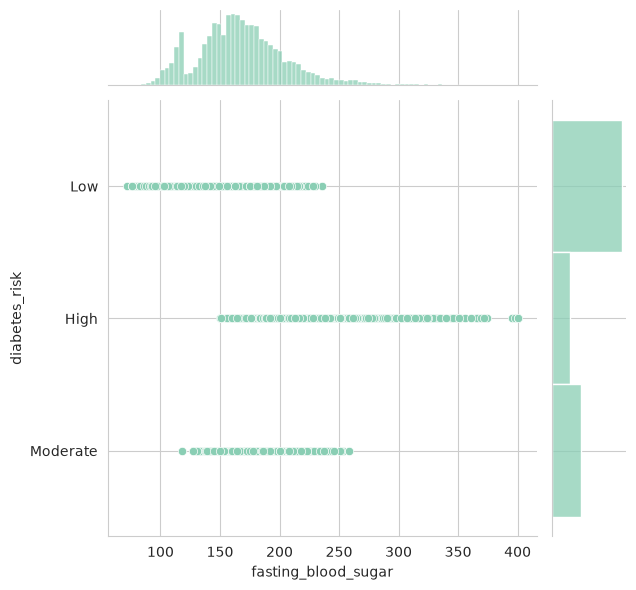

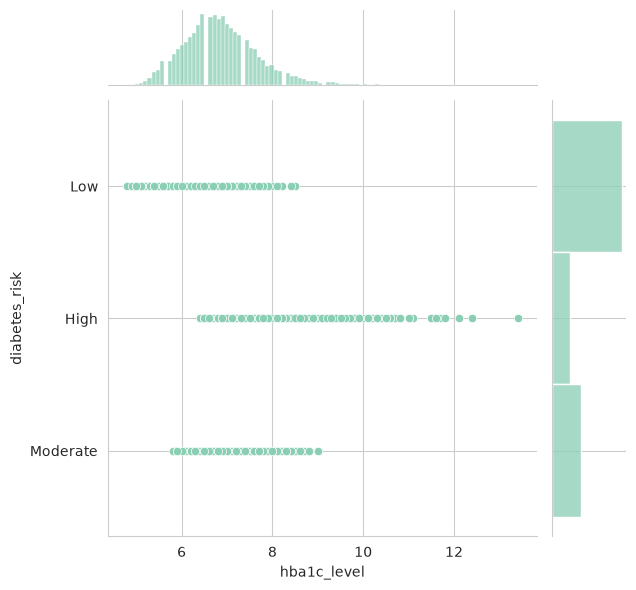

In [110]:
sns.set_palette("BuGn_d")
sns.set_style('whitegrid')
sns.jointplot(x = 'fasting_blood_sugar', y = 'diabetes_risk', data = info_df)
sns.jointplot(x = 'hba1c_level', y = 'diabetes_risk', data = info_df)

As predicted, fasting blood sugar and hba1c level at a glance both appear to have a high correlation with our target variable. To get a better picture of the full dataset however, we can create a heatmap and investigate correlations -

In [111]:

#healthpairplot = info_df[['age','gender', 'bmi', 'family_history_diabetes', 'physical_activity_level','diet_type','smoking_status',
#                            'alcohol_consumption','hours_sleep_per_night','stress_level','fasting_blood_sugar','hba1c_level',
#                            'blood_pressure_systolic','blood_pressure_diastolic','waist_circumference_cm','diabetes_risk']]
#sns.pairplot(healthpairplot)

<Axes: >

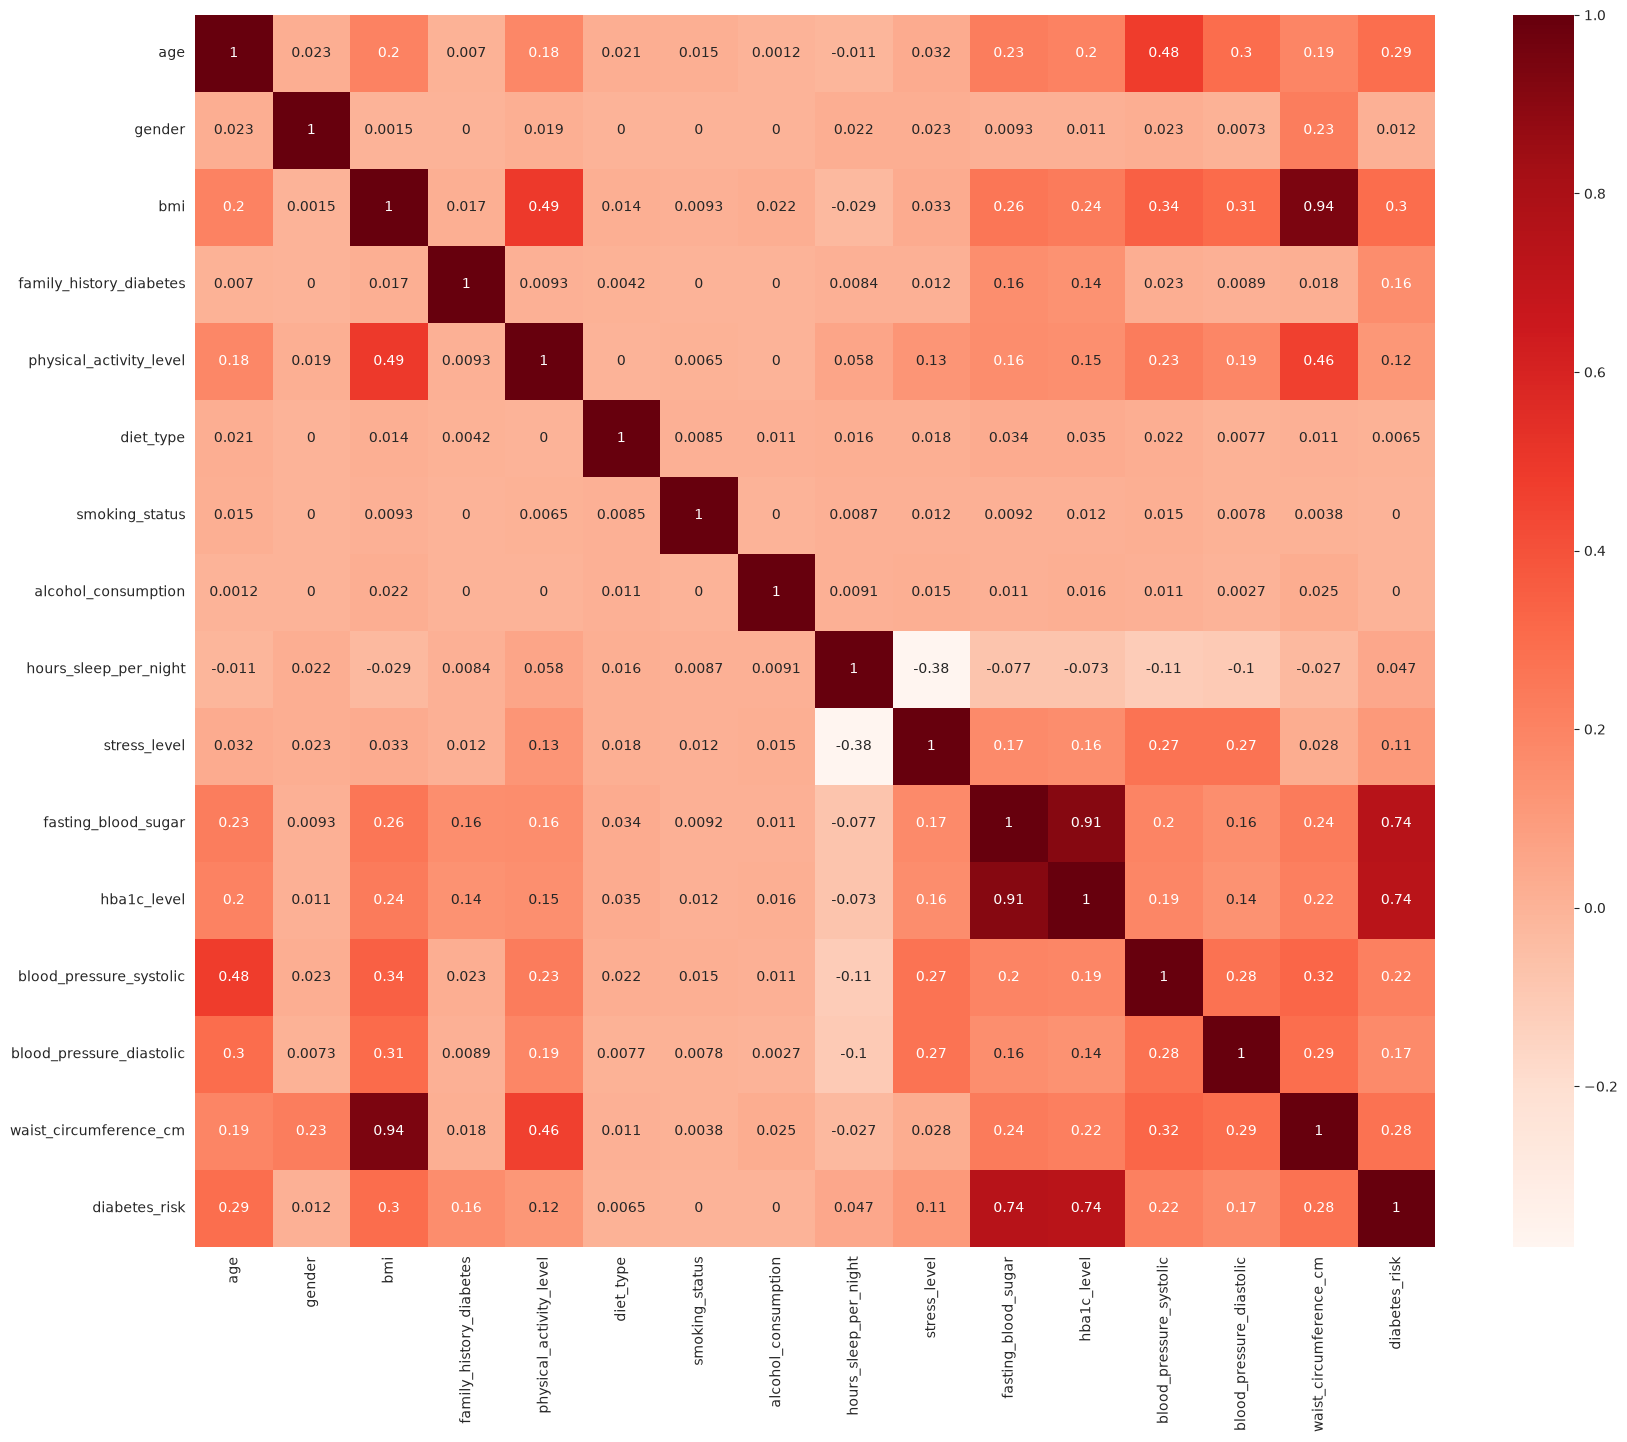

In [112]:
healthhmap = associations(info_df, nominal_columns=['gender','family_history_diabetes','physical_activity_level','diet_type','smoking_status','alcohol_consumption','diabetes_risk'], compute_only=True)
plt.figure(figsize=(20, 16))
sns.heatmap(healthhmap['corr'], cmap="Reds", annot=True)

Since there are a few columns with little to no correlation to our target diabetes risk, we can go ahead and drop those columns to simplify analysis.

In [113]:
info_df.drop(columns = ['gender','diet_type','smoking_status', 'alcohol_consumption'], inplace = True)

**Model 1: Naive-Bayes**

The goal in this section is to use the Naive-Bayes method to classify patients by diabetes risk. To begin we simply split our original data into training and testing sets.

In [114]:
np.random.seed(50)
data_randomized = info_df.sample(frac=1)
# 70% of the data used for training set
trainsize = round(len(data_randomized) * 0.7)

# Build training and testings sets for model, test data = 30%
training_set = data_randomized[:trainsize].reset_index(drop=True)
test_set = data_randomized[trainsize:].reset_index(drop=True)
# Confirm that dimensions match the original data
print(training_set.shape)
print(test_set.shape)

trainX = training_set.iloc[:,:-1]
trainy = training_set['diabetes_risk']
columnnames = trainX.columns
testX = test_set.iloc[:,:-1]
testy = test_set['diabetes_risk']


(7594, 12)
(3255, 12)


The dataset we are using contains both continuous features like BMI and blood sugar as well as discrete variables like physical activity level, so we'll need to encode the data before we can build our Naive-Bayes model.

In [115]:
categorical_columns = ['family_history_diabetes','physical_activity_level']
numerical_columns = [item for item in columnnames if item not in categorical_columns]

# checking if columns were properly sorted
print(categorical_columns)
print(numerical_columns)
# creating copies of train and test dataframes to store encoded data
trainX_enc = trainX.copy()
testX_enc = testX.copy()

# using OrdinalEncoder to do categorical features first
ordinalencoder = OrdinalEncoder (
    handle_unknown = "use_encoded_value",
    unknown_value = -1
)

# transforming categorical data within training
trainX_enc[categorical_columns] = ordinalencoder.fit_transform(trainX[categorical_columns])
# doing the same for test data but taking care to avoid using fit() to maintain encoding rules
testX_enc[categorical_columns] = ordinalencoder.transform(testX[categorical_columns])

# in case of an unknown, we add one here to avoid negatives
trainX_enc[categorical_columns] = trainX_enc[categorical_columns] + 1
testX_enc[categorical_columns] = testX_enc[categorical_columns] + 1


['family_history_diabetes', 'physical_activity_level']
['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']


Now that we have the categorical data encoded, we move onto the numerical data -

In [116]:
# first need to partition numerical into distinct bins
for column in numerical_columns:
  bins = pd.qcut(
    trainX_enc[column],
    q=10,
    duplicates="drop",
    retbins=True
  )[1]

  trainX_enc[column] = pd.cut(
    trainX_enc[column],
    bins=bins,
    include_lowest=True
  ).cat.codes

  testX_enc[column] = pd.cut(
    testX_enc[column],
    bins=bins,
    include_lowest=True
  ).cat.codes

# adding one like for the categorical columns to avoid negatives
trainX_enc[numerical_columns] = trainX_enc[numerical_columns] + 1
testX_enc[numerical_columns] = testX_enc[numerical_columns] + 1

# making sure data is stored as int
trainX_enc = trainX_enc.astype(int)
testX_enc = testX_enc.astype(int)

With our original dataframe encoded, we can now fit our model using the encoded training data.

In [117]:
# building Naive-Bayes model object
nbmodel = CategoricalNB()
# fit model
nbmodel.fit(trainX_enc, trainBrnli)
# predictions made using encoded training data
yhattrain = nbmodel.predict(trainX_enc)
# building confusion matrix to check accuracy (with rows representing predicted values)
pd.crosstab(yhattrain, trainy)


diabetes_risk,High,Low,Moderate
row_0,,,
0,816,11,221
1,15,3766,410
2,277,773,1305


From our confusion matrix we can see that our model was fairly accurate in predicting diabetes risk based on the training data, with the highest proportion of correctly identified diabetes risk factor being low, while moderate and high risk of diabetes being slightly less accurate. Another interesting insight to be gained here is that our model tends to incorrectly predict moderate risk at a much higher rate than the other levels. We can check the exact accuracy of our model on the training data by producing an accuracy score of correctly predicted outputs.

In [118]:
accuracy_score(yhattrain, trainBrnli)

0.7752172767974717

We need to now test this model on the testing data to ensure that our model is not overfitted. It is possible that the accuracy score for our test data is higher than our training data, though we can expect a lower accuracy score for the test data on average. Too great a discrepancy either way would mean our model is not reliable across all possible samples.

In [119]:
yhattest = nbmodel.predict(testX_enc)
pd.crosstab(yhattest, testBrnli)

col_0,0,1,2
row_0,,,
0,374,5,75
1,7,1636,190
2,148,316,504


In [120]:
accuracy_score(yhattest, testBrnli)

0.7723502304147466

Our model accuracy scores on both the training and testing data are very similar with the test accuracy being just slightly less than the training data as expected, so our Naive-Bayes model is complete! With more data points in the future the model has the potential to become even more accurate as well.